## Modelo Recomendador de Peliculas 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split, StratifiedKFold

In [2]:
calificaciones = pd.read_csv("ml-latest-small/ratings.csv")
peliculas = pd.read_csv("ml-latest-small/movies.csv")
titulo = peliculas.set_index("movieId")["title"]   # para traducir movieId → título

In [3]:
#Imprimiendo el dataframe de peliculas
peliculas.head()


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
#Imprimiendo el dataframe de las calificaciones
calificaciones.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [5]:
#Haciendo validaciones de los datos
n_usuarios = calificaciones["userId"].nunique()
n_peliculas = calificaciones["movieId"].nunique()
print("Calificaciones:", len(calificaciones))
print("Usuarios:", n_usuarios)
print("Películas con al menos una calificación:", n_peliculas)
print(f"Celdas llenas de la tabla usuario × película: {len(calificaciones) / (n_usuarios * n_peliculas):.1%}")

Calificaciones: 100836
Usuarios: 610
Películas con al menos una calificación: 9724
Celdas llenas de la tabla usuario × película: 1.7%


# Exploracion de los datos 


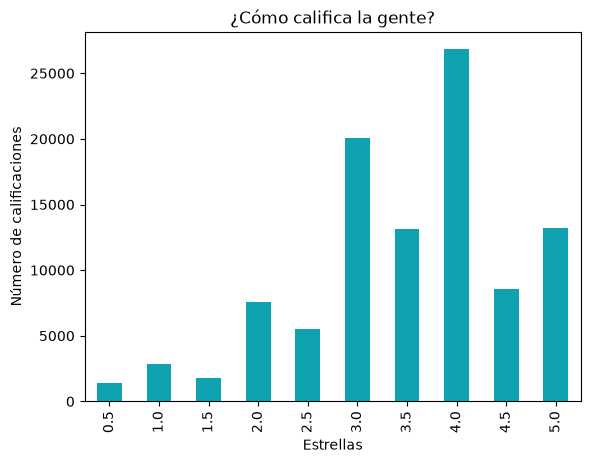

In [6]:
calificaciones["rating"].value_counts().sort_index().plot(kind="bar", color="#0FA3B1")
plt.title("¿Cómo califica la gente?")
plt.xlabel("Estrellas")
plt.ylabel("Número de calificaciones")
plt.show()

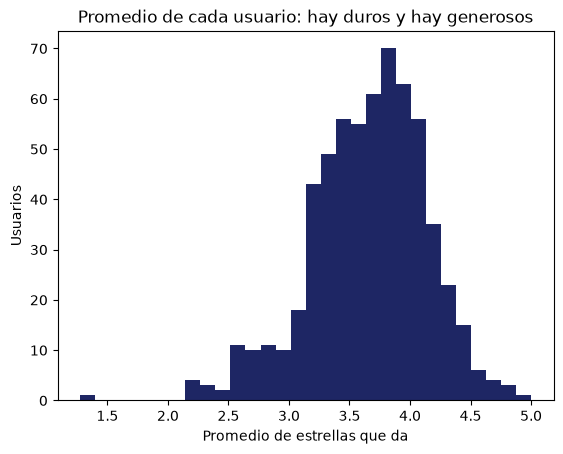

userId
442    1.275000
139    2.144330
508    2.145833
153    2.217877
567    2.245455
         ...   
30     4.735294
25     4.807692
515    4.846154
251    4.869565
53     5.000000
Name: rating, Length: 610, dtype: float64

In [7]:
#Distribucion de promedios por calificacion del usuario 
promedio_por_usuario = calificaciones.groupby("userId")["rating"].mean()
promedio_por_usuario.plot(kind="hist", bins=30, color="#1E2664")
plt.title("Promedio de cada usuario: hay duros y hay generosos")
plt.xlabel("Promedio de estrellas que da")
plt.ylabel("Usuarios")
plt.show()
promedio_por_usuario.sort_values()

In [8]:
conteo = calificaciones["movieId"].value_counts()   # calificaciones por película
print("Películas con UNA sola calificación:", (conteo == 1).sum())
print("Mediana de calificaciones por película:", conteo.median())
print("Mediana de calificaciones por película:", conteo.mean())

Películas con UNA sola calificación: 3446
Mediana de calificaciones por película: 3.0
Mediana de calificaciones por película: 10.369806663924312


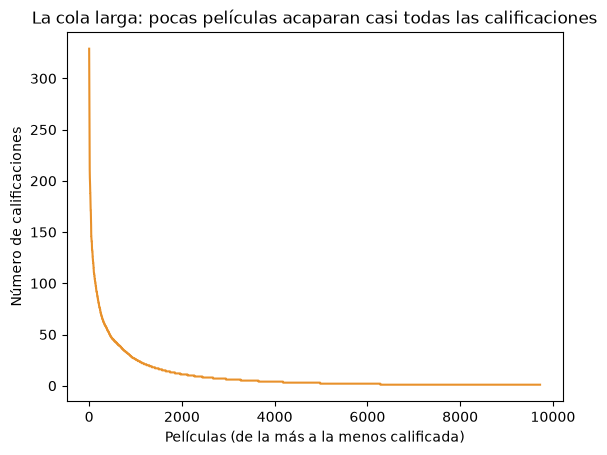

El 10 % más visto de las películas se lleva el 60% de las calificaciones


In [9]:
# ⌨️
plt.plot(conteo.values, color="#E8912B")
plt.title("La cola larga: pocas películas acaparan casi todas las calificaciones")
plt.xlabel("Películas (de la más a la menos calificada)")
plt.ylabel("Número de calificaciones")
plt.show()
top10 = int(len(conteo) * 0.10)
print(f"El 10 % más visto de las películas se lleva el {conteo.head(top10).sum() / conteo.sum():.0%} de las calificaciones")


# Incluyendo mi reseña

In [10]:
lista = [1, 3114, 78499, 4886, 6377, 8961, 50872, 68954, 60069, 4306, 364, 588, 5618, 134853, 152081, 106696,
         2571, 260, 1196, 4993, 5952, 7153, 4896, 6539, 480, 1270, 79132, 109487, 72998, 58559, 59315, 89745, 112852, 122904,
         356, 318, 1721, 8533, 3578, 296, 2959, 593, 858, 47, 48516,
         69122, 54503, 7451, 1258, 1997, 1407, 8957, 5679]
pd.set_option("display.max_rows", 60)
peliculas.set_index("movieId").loc[lista, ["title", "genres"]]

,title,genres
movieId,,
1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy
78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX
4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy
6377,Finding Nemo (2003),Adventure|Animation|Children|Comedy
8961,"Incredibles, The (2004)",Action|Adventure|Animation|Children|Comedy
50872,Ratatouille (2007),Animation|Children|Drama
68954,Up (2009),Adventure|Animation|Children|Drama
60069,WALL·E (2008),Adventure|Animation|Children|Romance|Sci-Fi


In [11]:
mis_calificaciones = {
    122904: 4,        # Deadpool
    78499: 5,       # Avengers: Endgame
    4886: 4,          # The Dark Knight
    4896: 4.5,          # Harry Potter I
    89745: 4.5,       # The avengers
    112852: 4,      # guardians of the galaxy
    6539: 4.5,          # Pirates of the Caribbean: The Curse of the Black Pearl
    109487	: 5,    #Interstellar
    1258: 4,     # The Shining
    48516: 4,    # The Departed
    1721: 4.5,     # Titanic
}
mi_perfil = pd.DataFrame({"userId": 0,
                          "movieId": list(mis_calificaciones.keys()),
                          "rating": list(mis_calificaciones.values())})
print("Calificaste", len(mi_perfil), "películas. Tu promedio:", round(mi_perfil["rating"].mean(), 2))

Calificaste 11 películas. Tu promedio: 4.36


In [ ]:
califificaciones = 